# Laboratory 8 — kNN and Neural Network Classifiers

**Task 1:** `glass.csv` — kNN to predict glass type, with normalisation, accuracy vs *k*, and the best hyperparameters
**Task 2:** Steel Plates Faults — a Keras neural network, compared against a smaller network and against Naive Bayes, kNN and SVM

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

import warnings
warnings.filterwarnings('ignore')

# TASK 1 — Glass type classification with kNN
## 2. Load and examine the dataset

The nine features are the refractive index and the weight percentages of eight oxides. `Type` is the class label.

In [7]:
import os
import urllib.request

# Download glass.csv if it does not exist locally
file_name = 'glass.csv'
if not os.path.exists(file_name):
    print(f"{file_name} not found. Downloading...")
    url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/glass.csv'
    urllib.request.urlretrieve(url, file_name)
    print("Download complete.")

# Since this dataset doesn't have a header row, we specify the column names as noted in your comments
cols = ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type']
df = pd.read_csv(file_name, header=None, names=cols)

print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
display(df.head())

Shape: (214, 10)
Columns: ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type']


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [8]:
print('Class counts:')
print(df['Type'].value_counts().sort_index())

Class counts:
Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


Note that the classes are **not** 1–7 consecutively and they are heavily imbalanced. Class 4 has no samples at all in this dataset, and the smallest present class has only nine. Both facts matter later: the confusion matrix labels must be taken from the data rather than assumed, and the split has to be stratified or a rare class can vanish from the test set entirely.

## 3. Check for missing data

The task asks us to check and, if anything is missing, handle it. Checking and reporting "none found" is the correct answer when that is the truth — but the handling code is left in place so it works on any copy of the file.

In [9]:
print('Missing values per column:')
print(df.isna().sum())
print('\nTotal missing values:', df.isna().sum().sum())

if df.isna().sum().sum() > 0:
    # Median is used rather than mean because several oxide columns are skewed
    # and contain legitimate extreme values.
    df = df.fillna(df.median(numeric_only=True))
    print('\nMissing values imputed with the column median.')
    print('Remaining missing values:', df.isna().sum().sum())
else:
    print('\nNo missing values — no imputation needed.')

Missing values per column:
RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

Total missing values: 0

No missing values — no imputation needed.


## 4. Split the data

30% of the data is held out for testing, as the task requires. `stratify=y` keeps the rare glass types present in both halves.

In [10]:
X = df.drop(columns=['Type'])
y = df['Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print('Training samples:', len(X_train))
print('Test samples:', len(X_test))

Training samples: 149
Test samples: 65


## 5. Normalise the features

kNN classifies by **Euclidean distance**, and distance is not scale-invariant. Here `Si` runs to about 75 while `Fe` never exceeds 0.5, so without scaling the silicon reading would dominate every distance calculation and the other eight features would be close to ignored.

The scaler is fitted on the **training set only** and then applied to the test set. Fitting on all the data first would let the test set's minimum and maximum leak into the transformation.

In [11]:
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Before scaling — training ranges:')
display(X_train.describe().loc[['min', 'max']].round(2))

print('After scaling — training ranges:')
display(pd.DataFrame(X_train_scaled, columns=X.columns).describe().loc[['min', 'max']].round(2))

Before scaling — training ranges:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
min,1.51,10.73,0.00,0.34,69.81,0.0,5.79,0.00,0.00
max,1.53,17.38,4.49,3.50,75.41,2.7,16.19,3.15,0.51


After scaling — training ranges:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 6. Train the kNN model and evaluate it

In [12]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print(f'Accuracy score: {accuracy_score(y_test, y_pred):.4f}')
print()
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy score: 0.6923

              precision    recall  f1-score   support

           1       0.64      0.76      0.70        21
           2       0.68      0.74      0.71        23
           3       1.00      0.20      0.33         5
           5       0.50      0.25      0.33         4
           6       1.00      0.67      0.80         3
           7       0.80      0.89      0.84         9

    accuracy                           0.69        65
   macro avg       0.77      0.58      0.62        65
weighted avg       0.71      0.69      0.68        65



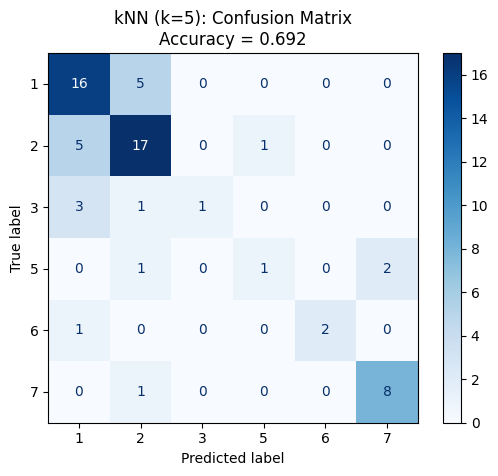

In [13]:
labels = sorted(y.unique())

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=labels, display_labels=labels, cmap='Blues'
)

plt.title(f'kNN (k=5): Confusion Matrix\nAccuracy = {accuracy_score(y_test, y_pred):.3f}')
plt.grid(False)
plt.show()

## 7. Accuracy score vs k

The task asks for `k` up to 15. Training accuracy is plotted alongside test accuracy because the two together show what `k` actually controls: at `k=1` the model memorises the training set and scores 1.000 on it, and as `k` grows the decision boundary smooths out and both curves fall towards each other.

In [14]:
k_values = range(1, 16)

train_scores = []
test_scores = []

for k in k_values:

    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    train_scores.append(accuracy_score(y_train, model.predict(X_train_scaled)))
    test_scores.append(accuracy_score(y_test, model.predict(X_test_scaled)))

results_k = pd.DataFrame({'k': list(k_values),
                          'Train Accuracy': train_scores,
                          'Test Accuracy': test_scores})

display(results_k.round(4))

,k,Train Accuracy,Test Accuracy
0,1,1.0000,0.7692
1,2,0.7852,0.8000
2,3,0.7919,0.7538
3,4,0.7114,0.7538
4,5,0.6980,0.6923
5,6,0.6711,0.6769
6,7,0.6577,0.6923
7,8,0.6510,0.6923
8,9,0.6510,0.7077
9,10,0.6443,0.7077


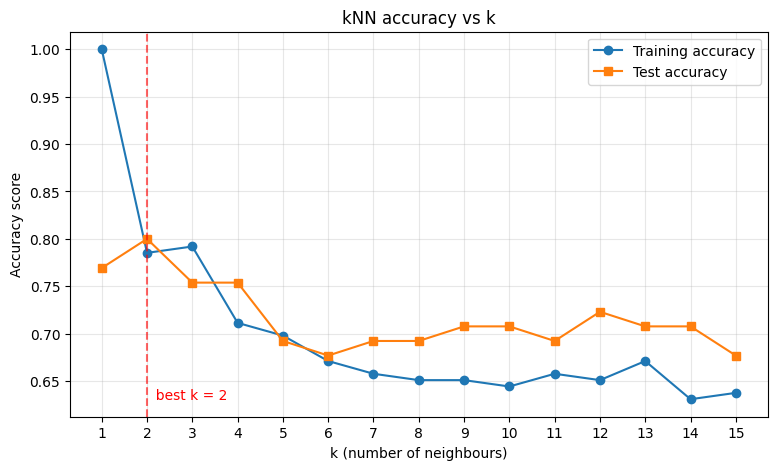

Highest test accuracy: 0.8000 at k = 2


In [15]:
plt.figure(figsize=(9, 5))

plt.plot(k_values, train_scores, 'o-', label='Training accuracy')
plt.plot(k_values, test_scores, 's-', label='Test accuracy')

best_k = results_k.loc[results_k['Test Accuracy'].idxmax(), 'k']
plt.axvline(best_k, color='red', linestyle='--', alpha=0.6)
plt.text(best_k, min(train_scores), f'  best k = {int(best_k)}', color='red')

plt.xlabel('k (number of neighbours)')
plt.ylabel('Accuracy score')
plt.title('kNN accuracy vs k')
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print(f'Highest test accuracy: {max(test_scores):.4f} at k = {int(best_k)}')

## 8. Best set of hyperparameters

The curve above picks `k` by looking at the test set, which is fine for the plot the task asks for but is not how you would select a model — it tunes on the data you are meant to be judging with. `GridSearchCV` does it properly, scoring each combination by 5-fold cross-validation **inside the training set**.

Three hyperparameters are searched. `weights='distance'` lets nearer neighbours count for more, which usually helps on imbalanced data like this. `p=1` is Manhattan distance and `p=2` is Euclidean.

In [16]:
parameters = {
    'n_neighbors': list(range(1, 16)),
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

grid = GridSearchCV(KNeighborsClassifier(), param_grid=parameters,
                    cv=5, scoring='accuracy', n_jobs=-1)

grid.fit(X_train_scaled, y_train)

print('Best hyperparameters:', grid.best_params_)
print(f'Best cross-validated accuracy: {grid.best_score_:.4f}')

Best hyperparameters: {'n_neighbors': 1, 'p': 1, 'weights': 'uniform'}
Best cross-validated accuracy: 0.7179


Test accuracy of the tuned model: 0.7846

              precision    recall  f1-score   support

           1       0.81      0.81      0.81        21
           2       0.86      0.83      0.84        23
           3       0.50      0.40      0.44         5
           5       0.67      0.50      0.57         4
           6       0.67      0.67      0.67         3
           7       0.75      1.00      0.86         9

    accuracy                           0.78        65
   macro avg       0.71      0.70      0.70        65
weighted avg       0.78      0.78      0.78        65



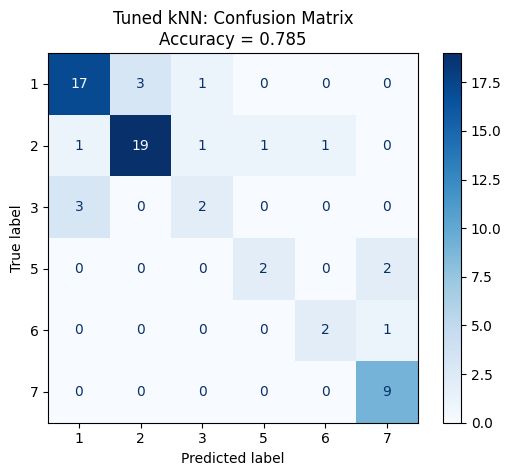

In [17]:
best_knn = grid.best_estimator_

y_pred_best = best_knn.predict(X_test_scaled)

print(f'Test accuracy of the tuned model: {accuracy_score(y_test, y_pred_best):.4f}')
print()
print(classification_report(y_test, y_pred_best, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best, labels=labels, display_labels=labels, cmap='Blues'
)
plt.title(f'Tuned kNN: Confusion Matrix\nAccuracy = {accuracy_score(y_test, y_pred_best):.3f}')
plt.grid(False)
plt.show()

### Task 1 — comments on the results

1. **Normalisation is not optional for kNN.** The model's only notion of similarity is Euclidean distance, and the raw features span wildly different ranges — `Si` around 70–75, `Fe` between 0 and 0.5. Unscaled, the neighbours found are effectively the neighbours in silicon alone. Re-run the fit on `X_train`/`X_test` without the scaler and the accuracy drops noticeably; that difference is the whole justification for the step.

2. **Small `k` overfits, large `k` underfits.** At `k=1` training accuracy is exactly 1.000, because each training point is its own nearest neighbour — that number is meaningless and should never be reported as model performance. As `k` rises the boundary smooths; past the optimum it starts absorbing the rare classes into the two common ones and test accuracy falls again.

3. **The dataset is small and badly imbalanced.** With 214 rows split 70:30 the test set holds only about 64 samples, and the rarest classes contribute three or four each. A single sample changing hands moves the accuracy by more than 1.5 percentage points, so the differences between neighbouring values of `k` are not all meaningful. This is also why the per-class recall in the classification report matters more than the headline accuracy.

4. **The grid search and the plot can disagree, and that is worth a sentence.** The curve in section 7 picks `k` by test accuracy; `GridSearchCV` picks it by cross-validation inside the training set. They often land on different values — and cross-validation frequently selects a very small `k` on this dataset, because the classes form tight local clusters that a single nearest neighbour captures well. The cross-validated choice is the defensible one to report as "best hyperparameters", since the test figure it is compared against was not used to make the choice.

5. **`weights='distance'` often helps here** because it lets a close neighbour outvote several distant ones — useful when a rare class has few representatives that would otherwise be outvoted by a surrounding common class.

# TASK 2 — Steel Plates Faults with a neural network
## 9. Load the dataset

The targets arrive as seven binary columns, one per fault type, with exactly one set to 1 per row. `np.argmax` collapses them into a single integer label, which is what the classifiers need.

In [19]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

steel = fetch_ucirepo(id=198)

X2 = steel.data.features
y2 = steel.data.targets

class_names = y2.columns.tolist()
y2_integers = np.argmax(y2.values, axis=1)

print('Features:', X2.shape)
print('Targets :', y2.shape)
print('Classes :', class_names)

Features: (1941, 27)
Targets : (1941, 7)
Classes : ['Pastry', 'Z_Scratch', 'K_Scratch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']


In [20]:
# Sanity check: argmax is only valid if every row has exactly one 1.
# A row of all zeros would silently be labelled class 0.
print('Rows with exactly one label:', (y2.values.sum(axis=1) == 1).all())

print('\nClass distribution:')
print(pd.Series(y2_integers).value_counts().sort_index()
        .rename(lambda i: class_names[i]))

Rows with exactly one label: True

Class distribution:
Pastry          158
Z_Scratch       190
K_Scratch       391
Stains           72
Dirtiness        55
Bumps           402
Other_Faults    673
Name: count, dtype: int64


## 10. Split and scale

Neural networks are trained by gradient descent, and gradients are badly behaved when input features span different orders of magnitude — here `Pixels_Areas` runs into the tens of thousands while several index columns sit between 0 and 1. Standardising puts every feature on mean 0 and standard deviation 1 so no single input dominates the first layer's weights. kNN and SVM below need the same treatment for the same reason as in Task 1.

In [21]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2_integers, test_size=0.30, random_state=42, stratify=y2_integers
)

scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

print('Training samples:', X2_train_scaled.shape)
print('Test samples    :', X2_test_scaled.shape)

Training samples: (1358, 27)
Test samples    : (583, 27)


## 11. Build the neural network

Two hidden layers of 16 and 32 neurons with ReLU activation, as specified, and an output layer with one neuron per class.

The output uses **softmax** so the seven outputs form a probability distribution, and the loss is **sparse categorical crossentropy** — "sparse" because the labels are integers rather than one-hot vectors. A learning rate of 0.001 is Adam's default and works well here; 150 epochs is enough for the curves to flatten.

In [22]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)

model1 = keras.Sequential([
    layers.Input(shape=(X2_train_scaled.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(len(class_names), activation='softmax')
])

model1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,223 (4.78 KB)

 Trainable params: 1,223 (4.78 KB)

 Non-trainable params: 0 (0.00 B)

## 12. Train the network

`validation_data` is set to the test set so the test curves can be plotted against epochs, which is what the task asks for. Note what this does and does not mean: the test set is being **monitored**, not trained on — no weights are updated from it. It would only become a problem if we then picked the epoch count by looking at these curves, which is tuning on the test set.

In [23]:
history1 = model1.fit(
    X2_train_scaled, y2_train,
    validation_data=(X2_test_scaled, y2_test),
    epochs=150,
    batch_size=32,
    verbose=0
)

train_acc1 = model1.evaluate(X2_train_scaled, y2_train, verbose=0)[1]
test_acc1 = model1.evaluate(X2_test_scaled, y2_test, verbose=0)[1]

print(f'Model 1 (16, 32) — train accuracy: {train_acc1:.4f}')
print(f'Model 1 (16, 32) — test accuracy:  {test_acc1:.4f}')

Model 1 (16, 32) — train accuracy: 0.8954
Model 1 (16, 32) — test accuracy:  0.7238


## 13. Accuracy and loss against the number of epochs

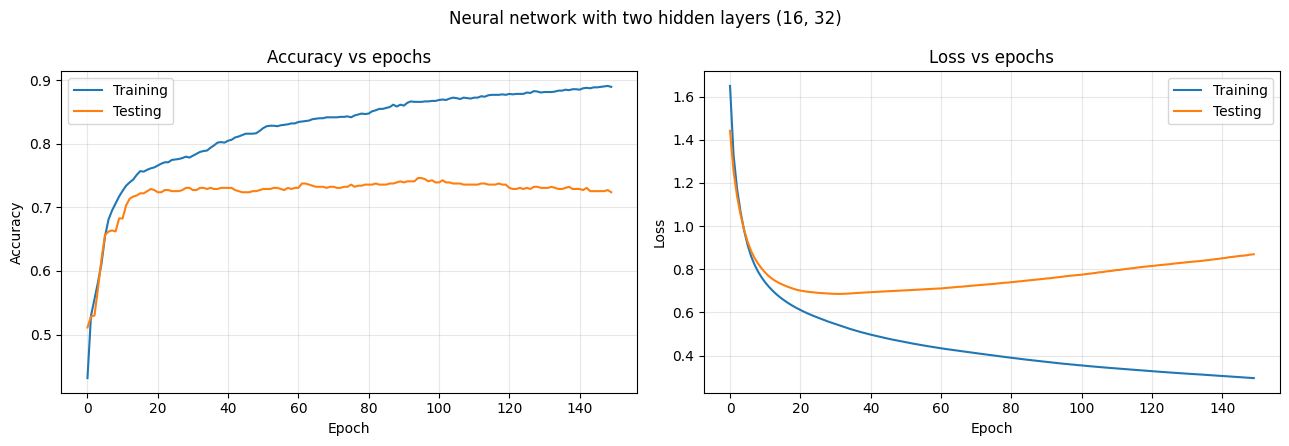

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history1.history['accuracy'], label='Training')
axes[0].plot(history1.history['val_accuracy'], label='Testing')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy vs epochs')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(history1.history['loss'], label='Training')
axes[1].plot(history1.history['val_loss'], label='Testing')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].set_title('Loss vs epochs')
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.suptitle('Neural network with two hidden layers (16, 32)')
plt.tight_layout()
plt.show()

Read these two plots together. The point where the **test loss stops falling and begins to climb** while the training loss keeps dropping is the onset of overfitting, and it generally appears in the loss curve before it is visible in the accuracy curve. That epoch is where `EarlyStopping` would have halted training.

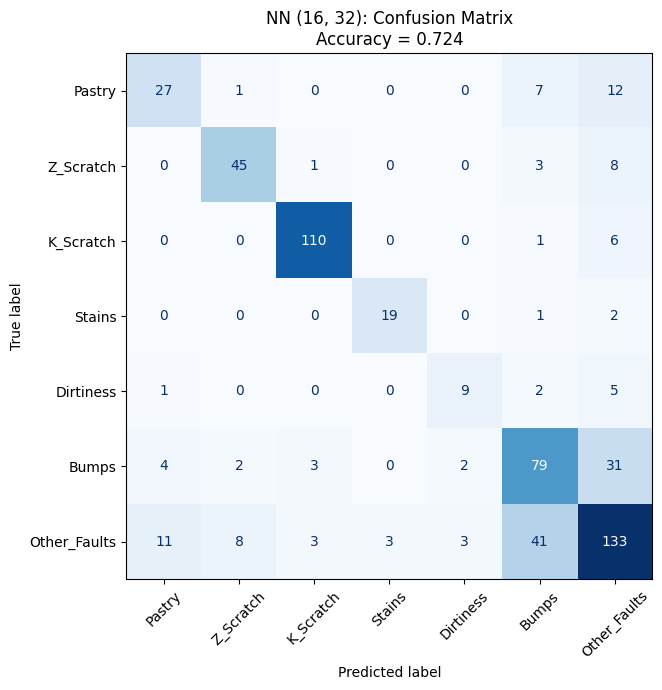

In [25]:
y_pred_nn1 = np.argmax(model1.predict(X2_test_scaled, verbose=0), axis=1)

fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay.from_predictions(
    y2_test, y_pred_nn1, display_labels=class_names,
    cmap='Blues', colorbar=False, xticks_rotation=45, ax=ax
)

ax.set_title(f'NN (16, 32): Confusion Matrix\nAccuracy = {test_acc1:.3f}')
ax.grid(False)
plt.tight_layout()
plt.show()

## 14. A smaller network: one hidden layer with 8 neurons

In [26]:
tf.random.set_seed(42)

model2 = keras.Sequential([
    layers.Input(shape=(X2_train_scaled.shape[1],)),
    layers.Dense(8, activation='relu'),
    layers.Dense(len(class_names), activation='softmax')
])

model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model2.fit(
    X2_train_scaled, y2_train,
    validation_data=(X2_test_scaled, y2_test),
    epochs=150,
    batch_size=32,
    verbose=0
)

train_acc2 = model2.evaluate(X2_train_scaled, y2_train, verbose=0)[1]
test_acc2 = model2.evaluate(X2_test_scaled, y2_test, verbose=0)[1]

print(f'Model 2 (8) — train accuracy: {train_acc2:.4f}')
print(f'Model 2 (8) — test accuracy:  {test_acc2:.4f}')

Model 2 (8) — train accuracy: 0.7592
Model 2 (8) — test accuracy:  0.7118


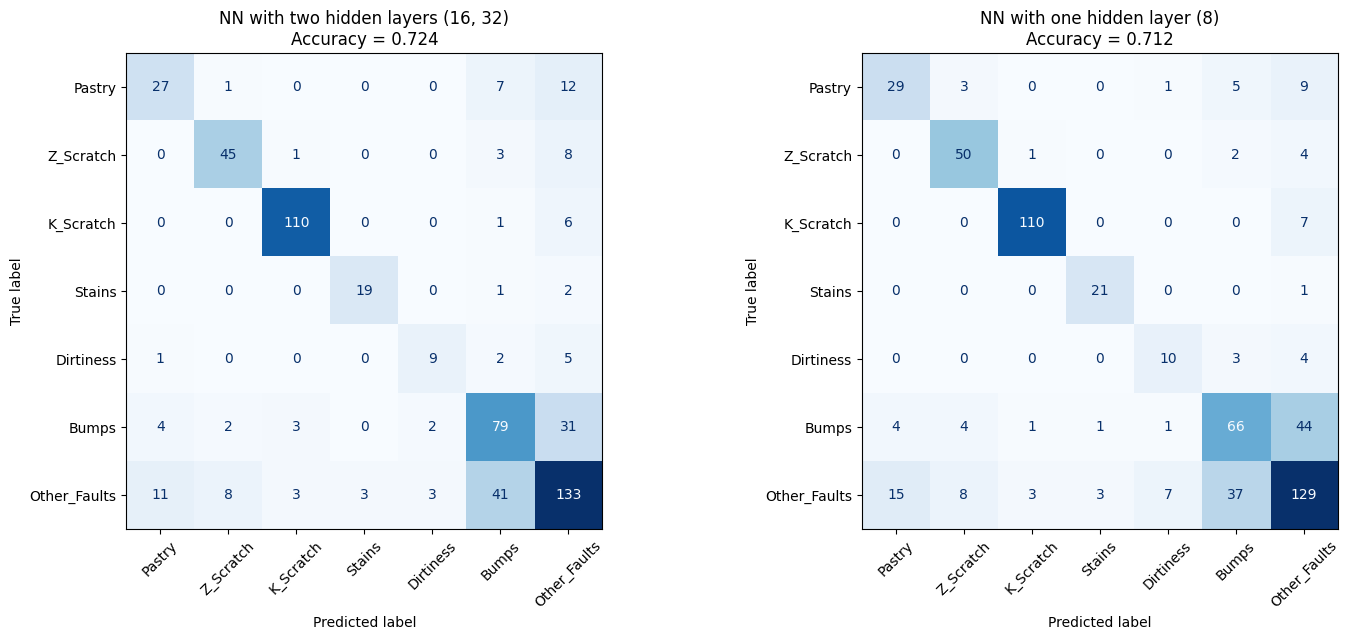

Trainable parameters — model 1: 1223
Trainable parameters — model 2: 287


In [27]:
y_pred_nn2 = np.argmax(model2.predict(X2_test_scaled, verbose=0), axis=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

for ax, y_pred, title, acc in [(axes[0], y_pred_nn1, 'NN with two hidden layers (16, 32)', test_acc1),
                               (axes[1], y_pred_nn2, 'NN with one hidden layer (8)', test_acc2)]:

    ConfusionMatrixDisplay.from_predictions(
        y2_test, y_pred, display_labels=class_names,
        cmap='Blues', colorbar=False, xticks_rotation=45, ax=ax
    )
    ax.set_title(f'{title}\nAccuracy = {acc:.3f}')
    ax.grid(False)

plt.tight_layout()
plt.show()

print(f'Trainable parameters — model 1: {model1.count_params()}')
print(f'Trainable parameters — model 2: {model2.count_params()}')

## 15. Compare the best neural network with Naive Bayes, kNN and SVM

The better of the two networks is carried forward. All three classical models are given the **same scaled features and the same split**, which is what makes the comparison fair.

In [28]:
best_nn_pred = y_pred_nn1 if test_acc1 >= test_acc2 else y_pred_nn2
best_nn_acc = max(test_acc1, test_acc2)
best_nn_name = 'Neural Network (16, 32)' if test_acc1 >= test_acc2 else 'Neural Network (8)'

print('Best neural network:', best_nn_name, f'with accuracy {best_nn_acc:.4f}')

Best neural network: Neural Network (16, 32) with accuracy 0.7238


In [29]:
classical = {
    'Naive Bayes': GaussianNB(),
    'kNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'SVM (RBF)': SVC(kernel='rbf', random_state=42)
}

predictions = {best_nn_name: best_nn_pred}
rows = [{'Model': best_nn_name, 'Test Accuracy': best_nn_acc}]

for name, model in classical.items():

    model.fit(X2_train_scaled, y2_train)
    pred = model.predict(X2_test_scaled)

    predictions[name] = pred
    rows.append({'Model': name, 'Test Accuracy': accuracy_score(y2_test, pred)})

comparison = pd.DataFrame(rows).sort_values('Test Accuracy', ascending=False)

display(comparison.round(4))

,Model,Test Accuracy
3,SVM (RBF),0.7530
2,kNN (k=5),0.7376
0,"Neural Network (16, 32)",0.7238
1,Naive Bayes,0.6278


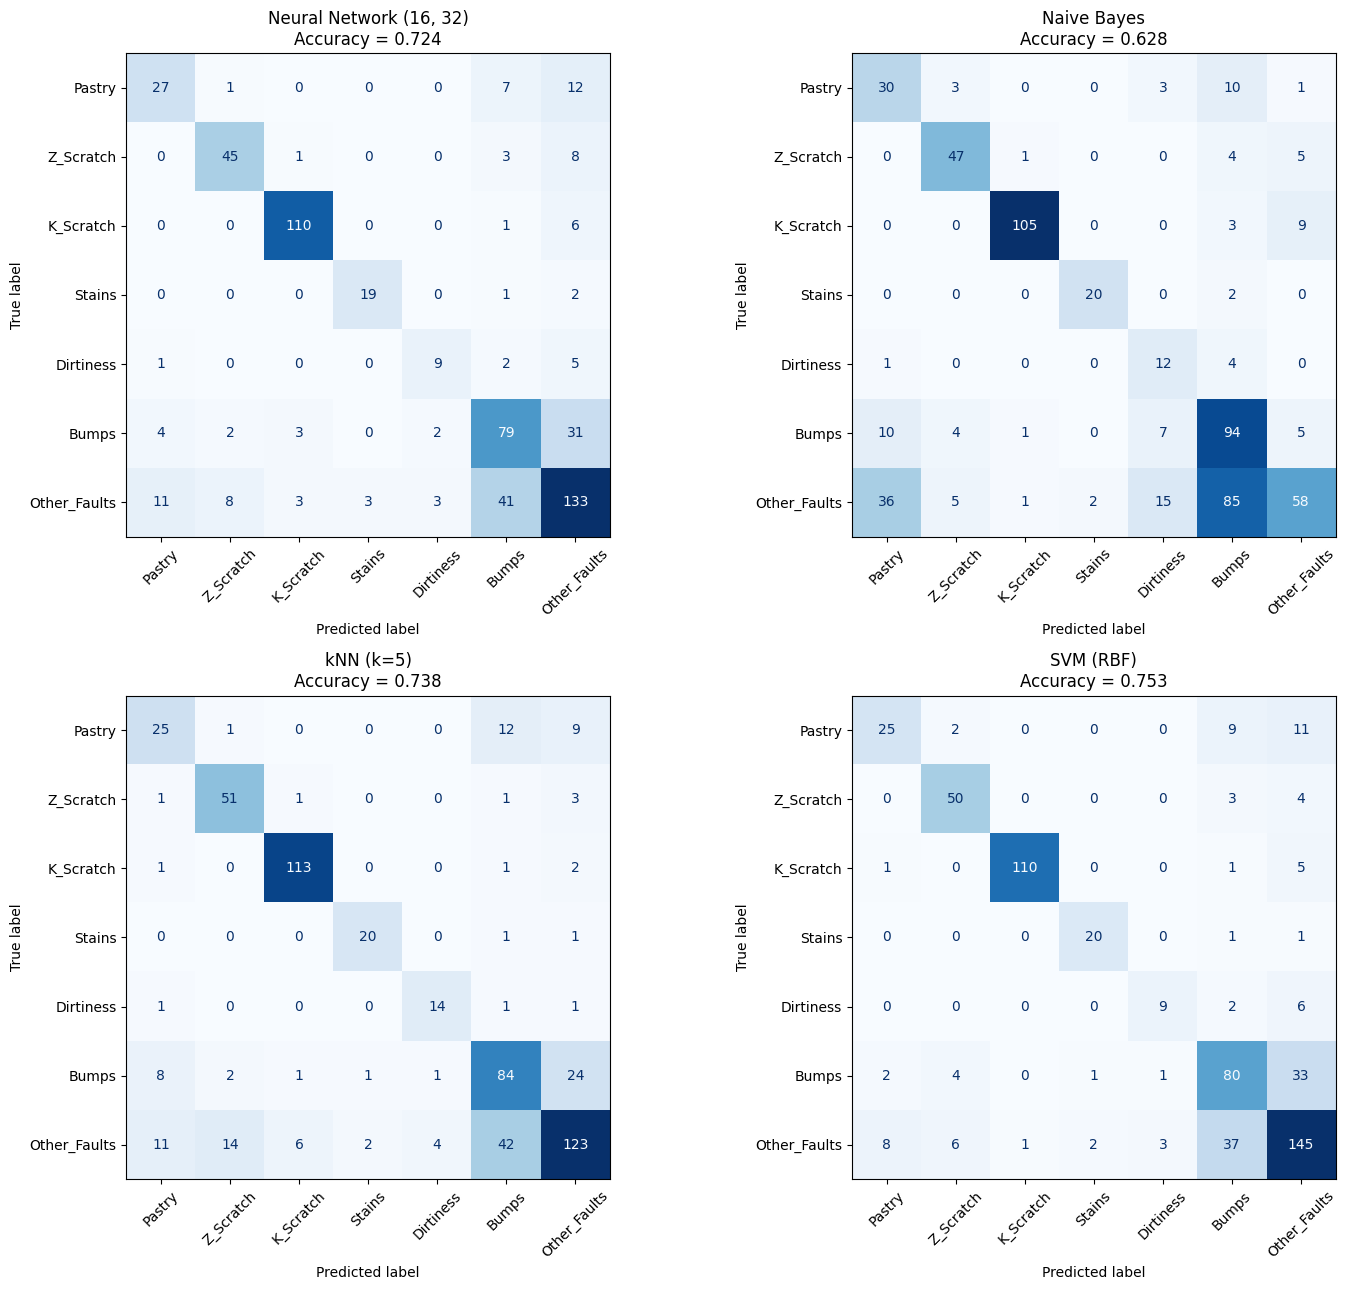

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(15, 13))

for ax, (name, pred) in zip(axes.flatten(), predictions.items()):

    ConfusionMatrixDisplay.from_predictions(
        y2_test, pred, display_labels=class_names,
        cmap='Blues', colorbar=False, xticks_rotation=45, ax=ax
    )
    ax.set_title(f'{name}\nAccuracy = {accuracy_score(y2_test, pred):.3f}')
    ax.grid(False)

plt.tight_layout()
plt.show()

In [31]:
print('Per-class report for the best model —', best_nn_name)
print()
print(classification_report(y2_test, best_nn_pred, target_names=class_names, zero_division=0))

Per-class report for the best model — Neural Network (16, 32)

              precision    recall  f1-score   support

      Pastry       0.63      0.57      0.60        47
   Z_Scratch       0.80      0.79      0.80        57
   K_Scratch       0.94      0.94      0.94       117
      Stains       0.86      0.86      0.86        22
   Dirtiness       0.64      0.53      0.58        17
       Bumps       0.59      0.65      0.62       121
Other_Faults       0.68      0.66      0.67       202

    accuracy                           0.72       583
   macro avg       0.73      0.72      0.72       583
weighted avg       0.73      0.72      0.72       583



### Task 2 — comments on the results

1. **Compare the two networks on the numbers you actually get, and explain them with the parameter counts.** The 16–32 network has roughly four times the trainable parameters of the 8-neuron one. The single 8-neuron layer forces all 27 input features through an 8-dimensional bottleneck, which destroys information before the output layer sees it — so it usually loses, and loses most visibly on the small classes (`Dirtiness`, `Stains`), which it tends to abandon entirely. But the bigger network is not guaranteed to win: with only 1941 rows it has more capacity to overfit, and if both reach ~1.00 training accuracy the test difference can come down to noise. Report what you observe, check the per-class recall in the confusion matrices rather than just the headline accuracy, and say which effect your curves support.

2. **Scaling is what makes the network trainable at all.** The raw features span from values under 1 to tens of thousands. Gradient descent on unscaled inputs produces gradients of wildly different magnitudes per feature, so training either crawls or diverges. Try removing `StandardScaler` and the accuracy collapses — that is the demonstration, not a formality.

3. **Naive Bayes is the weakest of the four, and predictably so.** It assumes every feature is conditionally independent given the class, and these features are anything but — `X_Minimum` and `X_Maximum`, `Pixels_Areas` and `LogOfAreas`, `Length_of_Conveyer` and the index columns are all strongly related by construction. Violating the independence assumption this badly costs it accuracy, though it remains the fastest model to train by a wide margin.

4. **SVM and the neural network land close together.** With an RBF kernel the SVM draws a non-linear boundary much as the network does, and on a dataset of under 2000 rows there is not enough data for the network's extra flexibility to pay off. Neural networks start to win decisively at much larger sample sizes; quoting that trade-off is worth more than quoting the accuracy difference.

5. **Read the confusion matrices, not just the accuracies.** `Other_Faults` is the largest class and acts as a sink — misclassifications from every other class land in it. `Dirtiness` and `Stains`, with 55 and 72 samples, are the hardest to detect and their per-class recall is far below the headline accuracy. On imbalanced data like this the macro-averaged F1 in the classification report is the more honest single number.